<a href="https://colab.research.google.com/github/VilasiniRamamoorthy/PlanetaryDenseAsteroidAnalytics/blob/main/Project2_Planetary_Defense_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Planetary Defense Analytics: Classifying and Predicting Asteroid Properties (V2)**

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('/content/pha_dataset.csv', low_memory=False)


In [ ]:
df.shape

(958524, 45)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 958524 entries, 0 to 958523
Data columns (total 45 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              958524 non-null  object 
 1   spkid           958524 non-null  int64  
 2   full_name       958524 non-null  object 
 3   pdes            958524 non-null  object 
 4   name            22064 non-null   object 
 5   prefix          18 non-null      object 
 6   neo             958520 non-null  object 
 7   pha             938603 non-null  object 
 8   H               952261 non-null  float64
 9   diameter        136209 non-null  float64
 10  albedo          135103 non-null  float64
 11  diameter_sigma  136081 non-null  float64
 12  orbit_id        958524 non-null  object 
 13  epoch           958524 non-null  float64
 14  epoch_mjd       958524 non-null  int64  
 15  epoch_cal       958524 non-null  float64
 16  equinox         958524 non-null  object 
 17  e         

In [ ]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [ ]:
df.describe()

,spkid,H,diameter,albedo,diameter_sigma,epoch,epoch_mjd,epoch_cal,e,a,...,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,rms
count,9.585240e+05,952261.000000,136209.000000,135103.000000,136081.000000,9.585240e+05,958524.000000,9.585240e+05,958524.000000,958524.000000,...,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.385980e+05,9.386020e+05,9.386020e+05,9.385980e+05,958522.000000
mean,3.810114e+06,16.906411,5.506429,0.130627,0.479184,2.458869e+06,58868.781950,2.019693e+07,0.156116,2.902143,...,1.982929e+01,1.168449e+00,5.310234e+00,1.370062e+06,1.369977e+06,2.131453e+01,5.060221e-02,4.312780e+08,8.525815e+04,0.561153
std,6.831541e+06,1.790405,9.425164,0.110323,0.782895,7.016716e+02,701.671573,1.930354e+04,0.092643,39.719503,...,2.903785e+03,1.282231e+02,1.333381e+03,9.158996e+08,9.158991e+08,7.197034e+03,9.814953e+00,2.953046e+11,2.767681e+07,2.745700
min,2.000001e+06,-1.100000,0.002500,0.001000,0.000500,2.425052e+06,25051.000000,1.927062e+07,0.000000,-14702.447872,...,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,0.000000
25%,2.239632e+06,16.100000,2.780000,0.053000,0.180000,2.459000e+06,59000.000000,2.020053e+07,0.092193,2.387835,...,1.462000e-07,6.095900e-06,3.619400e-05,5.755000e-05,2.573700e-05,2.340900e-08,2.768800e-09,1.110900e-04,1.794500e-05,0.518040
50%,2.479262e+06,16.900000,3.972000,0.079000,0.332000,2.459000e+06,59000.000000,2.020053e+07,0.145002,2.646969,...,2.271900e-07,8.688800e-06,6.642550e-05,1.047100e-04,4.900100e-05,4.359000e-08,4.638000e-09,2.230800e-04,3.501700e-05,0.566280
75%,3.752518e+06,17.714000,5.765000,0.190000,0.620000,2.459000e+06,59000.000000,2.020053e+07,0.200650,3.001932,...,6.583200e-07,1.591500e-05,1.609775e-04,3.114400e-04,1.718900e-04,1.196600e-07,1.124000e-08,8.139600e-04,9.775475e-05,0.613927
max,5.401723e+07,33.200000,939.400000,1.000000,140.000000,2.459000e+06,59000.000000,2.020053e+07,1.855356,33488.895955,...,1.015000e+06,5.533000e+04,1.199100e+06,8.845100e+11,8.845100e+11,5.509700e+06,7.698800e+03,2.853100e+14,1.910700e+10,2686.600000


In [ ]:
print(df["pha"].value_counts(dropna=False))

pha
N      936537
NaN     19921
Y        2066
Name: count, dtype: int64


In [ ]:
df = df.dropna(subset=["pha"]).copy()

print("Shape after removing missing PHA:", df.shape)

Shape after removing missing PHA: (938603, 45)


In [ ]:
df["pha"] = (
    df["pha"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({"Y": 1, "N": 0})
)

df = df.dropna(subset=["pha"]).copy()

df["pha"] = df["pha"].astype(int)

print(df["pha"].value_counts())

pha
0    936537
1      2066
Name: count, dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (938603, 45)


In [ ]:
drop_columns = [
    "id",
    "spkid",
    "pdes",
    "full_name",
    "name",
    "orbit_id",
    "moid",
    "moid_ld",
    "neo"
]

df = df.drop(
    columns=drop_columns,
    errors="ignore"
)

In [ ]:
sigma_columns = [
    col for col in df.columns
    if "sigma" in col.lower()
]

df = df.drop(
    columns=sigma_columns,
    errors="ignore"
)

print("Remaining columns:", df.columns.tolist())

Remaining columns: ['prefix', 'pha', 'H', 'diameter', 'albedo', 'epoch', 'epoch_mjd', 'epoch_cal', 'equinox', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'class', 'rms']


In [ ]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    )
})

missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print(missing)

           Missing_Count  Missing_Percentage
prefix            938585           99.998082
albedo            803500           85.605948
diameter          802394           85.488114
H                   6262            0.667162
ad                     4            0.000426
per                    4            0.000426
per_y                  1            0.000107
ma                     1            0.000107
rms                    1            0.000107
epoch_mjd              0            0.000000
epoch                  0            0.000000
pha                    0            0.000000
epoch_cal              0            0.000000
equinox                0            0.000000
a                      0            0.000000
e                      0            0.000000
w                      0            0.000000
om                     0            0.000000
i                      0            0.000000
q                      0            0.000000
tp_cal                 0            0.000000
tp        

In [ ]:
high_missing_columns = missing[
    missing["Missing_Percentage"] > 80
].index.tolist()

print("Columns with more than 80% missing:")
print(high_missing_columns)

Columns with more than 80% missing:
['prefix', 'albedo', 'diameter']


In [ ]:
df = df.drop(
    columns='prefix',
    errors="ignore"
)

In [ ]:
df = df.drop(
    columns='albedo',
    errors="ignore"
)

In [ ]:
import numpy as np

In [ ]:
print(df.select_dtypes(include=np.number).describe().T)

              count          mean           std           min           25%  \
pha        938603.0  2.201144e-03  4.686471e-02  0.000000e+00  0.000000e+00   
H          932341.0  1.688997e+01  1.801386e+00 -1.100000e+00  1.600000e+01   
diameter   136209.0  5.506429e+00  9.425164e+00  2.500000e-03  2.780000e+00   
albedo     135103.0  1.306272e-01  1.103228e-01  1.000000e-03  5.300000e-02   
epoch      938603.0  2.458871e+06  7.055064e+02  2.425052e+06  2.459000e+06   
epoch_mjd  938603.0  5.887092e+04  7.055064e+02  2.505100e+04  5.900000e+04   
epoch_cal  938603.0  2.019698e+07  1.940867e+04  1.927062e+07  2.020053e+07   
e          938603.0  1.561461e-01  9.300582e-02  0.000000e+00  9.206445e-02   
a          938603.0  2.906752e+00  4.013775e+01 -1.470245e+04  2.388114e+00   
q          938603.0  2.397725e+00  2.159374e+00  7.051073e-02  1.971656e+00   
i          938603.0  9.048065e+00  6.646721e+00  7.744220e-03  4.154593e+00   
om         938603.0  1.684496e+02  1.028745e+02  2.4

In [ ]:
if "e" in df.columns:
    df = df[df["e"] >= 0]

if "a" in df.columns:
    df = df[df["a"] > 0]

if "i" in df.columns:
    df = df[
        (df["i"] >= 0) &
        (df["i"] <= 180)
    ]

In [ ]:
df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

In [ ]:
zero_variance_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
    and col != "pha"
]

print("Zero variance columns:")
print(zero_variance_columns)

df = df.drop(
    columns=zero_variance_columns
)

Zero variance columns:
['equinox']


In [ ]:
unique_columns = [
    col for col in df.columns
    if col != "pha"
    and df[col].nunique(dropna=False) == len(df)
]

print("100% unique columns:", unique_columns)

df = df.drop(
    columns=unique_columns
)

100% unique columns: ['e', 'a', 'q', 'i', 'om', 'w', 'ad', 'n', 'per', 'per_y']


In [ ]:
X = df.drop(columns=["pha"])

y = df["pha"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (938599, 11)
Target shape: (938599,)


In [ ]:
numerical_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

Numerical columns: ['H', 'diameter', 'albedo', 'epoch', 'epoch_mjd', 'epoch_cal', 'ma', 'tp', 'tp_cal', 'rms']
Categorical columns: ['class']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Training class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("Testing class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training shape: (750879, 11)
Testing shape: (187720, 11)
Training class distribution:
pha
0    99.779858
1     0.220142
Name: proportion, dtype: float64
Testing class distribution:
pha
0    99.779991
1     0.220009
Name: proportion, dtype: float64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

In [ ]:
print(y.value_counts())

print(y.value_counts(normalize=True) * 100)

pha
0    936533
1      2066
Name: count, dtype: int64
pha
0    99.779885
1     0.220115
Name: proportion, dtype: float64


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

lr_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed")

Logistic Regression training completed


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

# Train the model
gb_pipeline.fit(X_train, y_train)

print("Gradient Boosting training completed")

Gradient Boosting training completed


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_balanced = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_balanced.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['H', 'diameter', 'albedo',
                                                   'epoch', 'epoch_mjd',
                                                   'epoch_cal', 'ma', 'tp',
                                                   'tp_cal', 'rms']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['class'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', n_jobs=-1,
                                        random_state=42))])

In [239]:
import joblib

# Save the trained Random Forest classification pipeline
joblib.dump(
    rf_balanced,
    "asteroid_pha_model.pkl"
)

print("Case 1 PHA model saved successfully!")

Case 1 PHA model saved successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Evaluation function
def evaluate_model(model, X_test, y_test, model_name):

    y_pred = model.predict(X_test)

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    }


# Store model results
results = []

# Without class balancing
results.append(
    evaluate_model(
        rf_pipeline, X_test, y_test,
        "Random Forest - Without Balancing"
    )
)

results.append(
    evaluate_model(
        lr_pipeline, X_test, y_test,
        "Logistic Regression - Without Balancing"
    )
)

results.append(
    evaluate_model(
        gb_pipeline, X_test, y_test,
        "Gradient Boosting - Without Balancing"
    )
)


# Convert results into DataFrame
results_df = pd.DataFrame(results)

print(results_df.round(4))

                                     Model  Accuracy  Precision  Recall  \
0        Random Forest - Without Balancing    0.9978     0.4854  0.2010   
1  Logistic Regression - Without Balancing    0.9975     0.3311  0.1186   
2    Gradient Boosting - Without Balancing    0.9978     0.2000  0.0024   

   F1 Score  
0    0.2842  
1    0.1747  
2    0.0048  


In [ ]:
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# --------------------------------
# 1. Logistic Regression - Balanced
# --------------------------------

lr_balanced = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

lr_balanced.fit(X_train, y_train)

print("Logistic Regression Balanced - Training completed")


# --------------------------------
# 2. Random Forest - Balanced
# --------------------------------

rf_balanced = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_balanced.fit(X_train, y_train)

print("Random Forest Balanced - Training completed")


# --------------------------------
# 3. Evaluate balanced models
# --------------------------------

results.append(
    evaluate_model(
        lr_balanced,
        X_test,
        y_test,
        "Logistic Regression - Balanced"
    )
)

results.append(
    evaluate_model(
        rf_balanced,
        X_test,
        y_test,
        "Random Forest - Balanced"
    )
)


# --------------------------------
# 4. Display comparison
# --------------------------------

results_df = pd.DataFrame(results)

print("\nModel Performance Comparison:")
print(results_df.round(4).to_string(index=False))

Logistic Regression Balanced - Training completed
Random Forest Balanced - Training completed

Model Performance Comparison:
                         Model                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

In [ ]:
Q1 = df["H"].quantile(0.25)
Q3 = df["H"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["H"] < lower_limit) |
    (df["H"] > upper_limit)
]

print("Outliers in H:", len(outliers))

Outliers in H: 44538


In [ ]:
# Calculate IQR limits for H
Q1 = df["H"].quantile(0.25)
Q3 = df["H"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify outliers
h_outliers = df[
    (df["H"] < lower_limit) |
    (df["H"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outliers:", len(h_outliers))

display(h_outliers["H"].describe())

Lower limit: 13.679000000000006
Upper limit: 20.134999999999994
Number of outliers: 44538


,H
count,44538.000000
mean,17.544055
std,6.219502
min,-1.100000
25%,12.888000
50%,13.600000
75%,23.200000
max,33.200000


**Regression**

In [ ]:
import pandas as pd
import numpy as np

# Make a separate copy of the original dataset
df_reg = df.copy()

# Convert diameter to numeric
df_reg["diameter"] = pd.to_numeric(
    df_reg["diameter"],
    errors="coerce"
)

# Remove rows where target diameter is missing
df_reg = df_reg.dropna(subset=["diameter"]).copy()

# Remove invalid diameter values
df_reg = df_reg[df_reg["diameter"] > 0].copy()

# Remove duplicate records
df_reg = df_reg.drop_duplicates().copy()

# Remove identifier and label columns
drop_columns = [
    "id", "spkid", "pdes",
    "full_name", "name", "orbit_id",
    "pha", "neo"
]

df_reg = df_reg.drop(
    columns=drop_columns,
    errors="ignore"
)

# Remove sigma uncertainty columns
sigma_columns = [
    col for col in df_reg.columns
    if "sigma" in col.lower()
]

df_reg = df_reg.drop(
    columns=sigma_columns,
    errors="ignore"
)

# Replace infinity values with NaN
df_reg = df_reg.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Shape after cleaning:", df_reg.shape)

print("\nMissing values:")
print(df_reg.isnull().sum())

print("\nFirst five records:")
print(df_reg.head())

Shape after cleaning: (136209, 11)

Missing values:
H            4164
diameter        0
albedo       1109
epoch           0
epoch_mjd       0
epoch_cal       0
ma              0
tp              0
tp_cal          0
class           0
rms             0
dtype: int64

First five records:
      H  diameter  albedo      epoch  epoch_mjd   epoch_cal          ma  \
0  3.40   939.400  0.0900  2458600.5      58600  20190427.0   77.372098   
1  4.20   545.000  0.1010  2459000.5      59000  20200531.0  144.975675   
2  5.33   246.596  0.2140  2459000.5      59000  20200531.0  125.435355   
3  3.00   525.400  0.4228  2458600.5      58600  20190427.0   95.861938   
4  6.90   106.699  0.2740  2459000.5      59000  20200531.0   17.846343   

             tp        tp_cal class      rms  
0  2.458239e+06  2.018043e+07   MBA  0.43301  
1  2.458321e+06  2.018072e+07   MBA  0.35936  
2  2.458446e+06  2.018112e+07   MBA  0.33848  
3  2.458248e+06  2.018051e+07   MBA  0.39980  
4  2.458926e+06  2.020032e+07 

In [ ]:
# Target variable
y = df_reg["diameter"]

# Independent features
X = df_reg.drop(columns=["diameter"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (136209, 10)
Target shape: (136209,)


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),

        ("cat", SimpleImputer(strategy="most_frequent"), categorical_features)
    ],
    remainder="drop"
)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (108967, 10)
Testing data: (27242, 10)


In [ ]:
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

In [ ]:
print("Regression dataset:", df_reg.shape)
print("Available diameter records:", len(y))
print("Number of features:", X.shape[1])
print("Missing target values:", y.isnull().sum())
print("Minimum diameter:", y.min())
print("Maximum diameter:", y.max())

Regression dataset: (136209, 11)
Available diameter records: 136209
Number of features: 10
Missing target values: 0
Minimum diameter: 0.0025
Maximum diameter: 939.4


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (108967, 10)
X_test: (27242, 10)
y_train: (108967,)
y_test: (27242,)


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = SimpleImputer(
    strategy="median"
)

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['H', 'albedo', 'epoch', 'epoch_mjd', 'epoch_cal', 'ma', 'tp', 'tp_cal', 'rms']
Categorical features: ['class']


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.pipeline import Pipeline

# Define three models
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# Store model results
results = []

trained_models = {}

# Train each model
for name, model in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict diameter
    y_pred = pipeline.predict(X_test)

    # Save trained pipeline
    trained_models[name] = pipeline

    # Store predictions and model
    results.append({
        "Model": name,
        "Predictions": y_pred
    })

    print("Training completed:", name)


Training: Linear Regression
Training completed: Linear Regression

Training: Random Forest
Training completed: Random Forest

Training: Gradient Boosting
Training completed: Gradient Boosting


In [ ]:
import numpy as np

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

comparison_results = []

for result in results:

    name = result["Model"]
    y_pred = result["Predictions"]

    r2 = r2_score(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    mae = mean_absolute_error(
        y_test, y_pred
    )

    comparison_results.append({
        "Model": name,
        "R2 Score": r2,
        "RMSE": rmse,
        "MAE": mae
    })

# Create comparison table
comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.sort_values(
    by="R2 Score",
    ascending=False
))

               Model  R2 Score      RMSE       MAE
1      Random Forest  0.936412  2.532735  0.456227
2  Gradient Boosting  0.933145  2.596978  0.492606
0  Linear Regression  0.362865  8.017119  2.701211


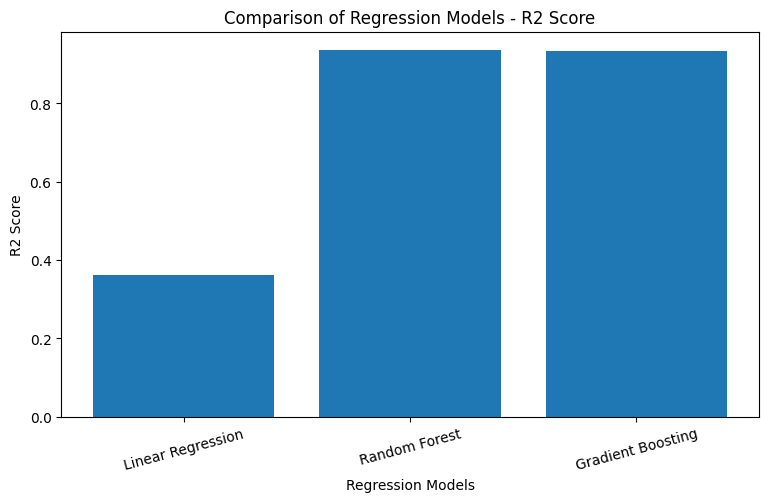

In [ ]:
import matplotlib.pyplot as plt

# R2 score comparison
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["R2 Score"]
)

plt.title("Comparison of Regression Models - R2 Score")
plt.xlabel("Regression Models")
plt.ylabel("R2 Score")

plt.xticks(rotation=15)
plt.show()

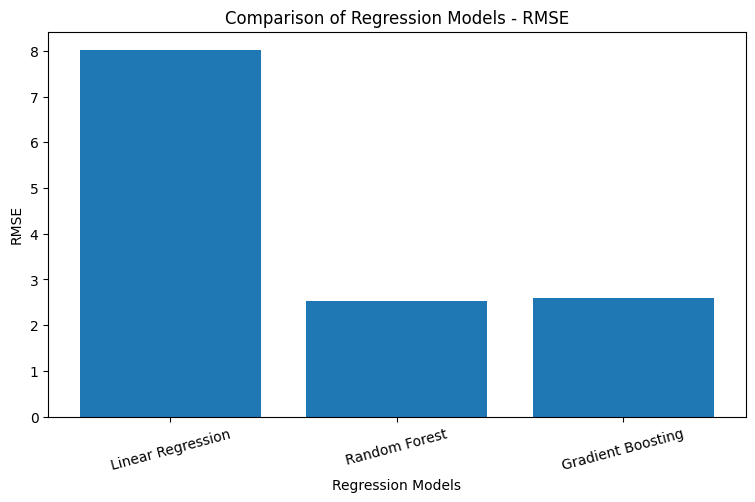

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["RMSE"]
)

plt.title("Comparison of Regression Models - RMSE")
plt.xlabel("Regression Models")
plt.ylabel("RMSE")

plt.xticks(rotation=15)
plt.show()

In [ ]:
best_model_name = comparison_df.sort_values(
    by="R2 Score",
    ascending=False
).iloc[0]["Model"]

print("Best Regression Model:", best_model_name)

Best Regression Model: Random Forest


In [ ]:
#best model
best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)

Selected model: Random Forest


In [240]:
import joblib

joblib.dump(
    best_model,
    "best_asteroid_regression_model.pkl"
)

print("Best regression model saved successfully!")

Best regression model saved successfully!


In [ ]:
print(
    comparison_df.sort_values(
        by="R2 Score",
        ascending=False
    ).to_string(index=False)
)

            Model  R2 Score     RMSE      MAE
    Random Forest  0.936412 2.532735 0.456227
Gradient Boosting  0.933145 2.596978 0.492606
Linear Regression  0.362865 8.017119 2.701211


In [ ]:
best_predictions = best_model.predict(X_test)

prediction_comparison = pd.DataFrame({
    "Actual Diameter": y_test.values,
    "Predicted Diameter": best_predictions
})

print(prediction_comparison.head(10))

   Actual Diameter  Predicted Diameter
0            2.509            2.683278
1            8.049            8.501473
2            2.363            2.392352
3           10.382            8.919350
4            1.783            1.832199
5            2.934            2.914335
6            3.160            3.377430
7            1.736            1.652840
8            3.643            3.172713
9            2.130            2.635295


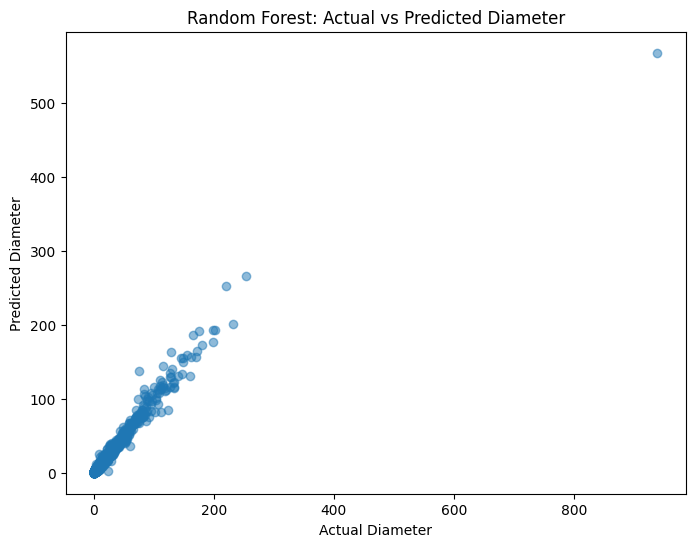

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

plt.xlabel("Actual Diameter")
plt.ylabel("Predicted Diameter")
plt.title("Random Forest: Actual vs Predicted Diameter")

plt.show()

In [ ]:
import json
import pandas as pd
import numpy as np

feature_schema = {}

# Use the actual trained classification model
for pipeline in [rf_balanced, best_model]:

    for col in pipeline.feature_names_in_:

        if col not in feature_schema:

            if col in df.columns:

                if pd.api.types.is_numeric_dtype(df[col]):
                    feature_schema[col] = "numeric"
                else:
                    feature_schema[col] = "categorical"

            else:
                raise ValueError(
                    f"Feature {col} not found in original dataset"
                )

# Save the schema
with open("feature_schema.json", "w") as f:
    json.dump(feature_schema, f, indent=4)

print("Feature schema saved successfully!")
print(feature_schema)

Feature schema saved successfully!
{'H': 'numeric', 'diameter': 'numeric', 'albedo': 'numeric', 'epoch': 'numeric', 'epoch_mjd': 'numeric', 'epoch_cal': 'numeric', 'ma': 'numeric', 'tp': 'numeric', 'tp_cal': 'numeric', 'class': 'categorical', 'rms': 'numeric'}


In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1


In [241]:
import json

feature_schema = {
    "H": "numeric",
    "diameter": "numeric",
    "albedo": "numeric",
    "epoch": "numeric",
    "epoch_mjd": "numeric",
    "epoch_cal": "numeric",
    "ma": "numeric",
    "tp": "numeric",
    "tp_cal": "numeric",
    "class": "categorical",
    "rms": "numeric"
}

with open("feature_schema.json", "w") as file:
    json.dump(feature_schema, file, indent=4)

print("Feature schema saved successfully!")

Feature schema saved successfully!
